In [26]:
import pandas as pd
import numpy as np

df=pd.read_csv(r"E:/Laptop_Price_Prediction/data/computer_prices_all.csv")
df.head()

,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,cpu_cores,...,resolution,refresh_hz,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price
0,Desktop,Samsung,Samsung Forge XDI,2022,Windows,ATX,Intel,Intel i5-11129,3,12,...,2560x1440,90,0,0,750,Wi-Fi 6,5.1,11.00,36,1383.99
1,Laptop,Samsung,Samsung Pro KM8,2022,Windows,Mainstream,Intel,Intel i7-11114,4,12,...,1920x1080,90,56,120,0,Wi-Fi 6,5.3,2.03,12,2274.99
2,Desktop,Lenovo,Lenovo Strix BIE,2024,macOS,SFF,AMD,AMD Ryzen 5 5168,2,8,...,3440x1440,120,0,0,850,Wi-Fi 6,5.0,7.00,24,1879.99
3,Desktop,Dell,Dell Cube AXR,2024,Windows,ATX,AMD,AMD Ryzen 5 7550,2,6,...,3440x1440,120,0,0,650,Wi-Fi 6,5.2,6.00,36,1331.99
4,Laptop,Gigabyte,Gigabyte Pro IX1,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,16,...,2560x1600,90,80,90,0,Wi-Fi 6,5.2,1.50,12,2681.99


In [27]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicated rows:")
print(df.duplicated().sum())

Shape: (100000, 33)

Columns:
['device_type', 'brand', 'model', 'release_year', 'os', 'form_factor', 'cpu_brand', 'cpu_model', 'cpu_tier', 'cpu_cores', 'cpu_threads', 'cpu_base_ghz', 'cpu_boost_ghz', 'gpu_brand', 'gpu_model', 'gpu_tier', 'vram_gb', 'ram_gb', 'storage_type', 'storage_gb', 'storage_drive_count', 'display_type', 'display_size_in', 'resolution', 'refresh_hz', 'battery_wh', 'charger_watts', 'psu_watts', 'wifi', 'bluetooth', 'weight_kg', 'warranty_months', 'price']

Data types:
device_type             object
brand                   object
model                   object
release_year             int64
os                      object
form_factor             object
cpu_brand               object
cpu_model               object
cpu_tier                 int64
cpu_cores                int64
cpu_threads              int64
cpu_base_ghz           float64
cpu_boost_ghz          float64
gpu_brand               object
gpu_model               object
gpu_tier                 int64
vram_gb   

In [28]:
print("\n",df.select_dtypes(include=['object']).head())
print("\n",df.select_dtypes(include=['float']).head())


   device_type     brand              model       os form_factor cpu_brand  \
0     Desktop   Samsung  Samsung Forge XDI  Windows         ATX     Intel   
1      Laptop   Samsung    Samsung Pro KM8  Windows  Mainstream     Intel   
2     Desktop    Lenovo   Lenovo Strix BIE    macOS         SFF       AMD   
3     Desktop      Dell      Dell Cube AXR  Windows         ATX       AMD   
4      Laptop  Gigabyte   Gigabyte Pro IX1    Linux      Gaming       AMD   

          cpu_model gpu_brand     gpu_model storage_type display_type  \
0    Intel i5-11129    NVIDIA     RTX 40 60         NVMe          LED   
1    Intel i7-11114    NVIDIA     RTX 40 80         NVMe         OLED   
2  AMD Ryzen 5 5168    NVIDIA     RTX 40 50         NVMe          LED   
3  AMD Ryzen 5 7550       AMD    RX 7000 60          HDD          IPS   
4  AMD Ryzen 7 6230    NVIDIA  RTX 30 80 Ti         NVMe     Mini-LED   

  resolution     wifi  
0  2560x1440  Wi-Fi 6  
1  1920x1080  Wi-Fi 6  
2  3440x1440  Wi-Fi 6  


In [29]:
df['price'] = df['price'].round(0).astype(int)
df['price']

0        1384
1        2275
2        1880
3        1332
4        2682
         ... 
99995    1713
99996    1259
99997    1687
99998    2165
99999    3006
Name: price, Length: 100000, dtype: int64

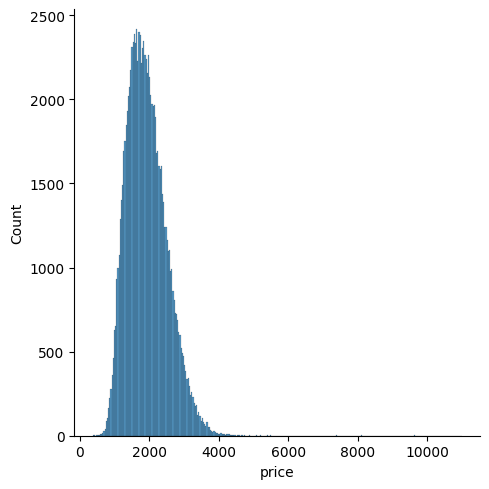

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.displot(df['price'])

<Axes: xlabel='brand'>

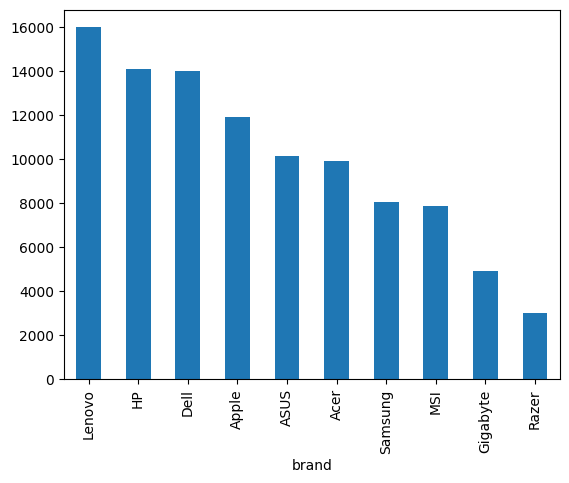

In [31]:
df['brand'].value_counts().plot(kind='bar')

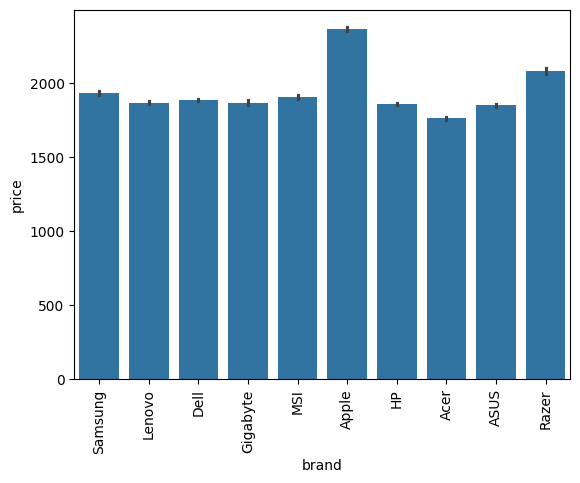

In [32]:
sns.barplot(x=df['brand'],y=df['price'])
plt.xticks(rotation='vertical')
plt.show()

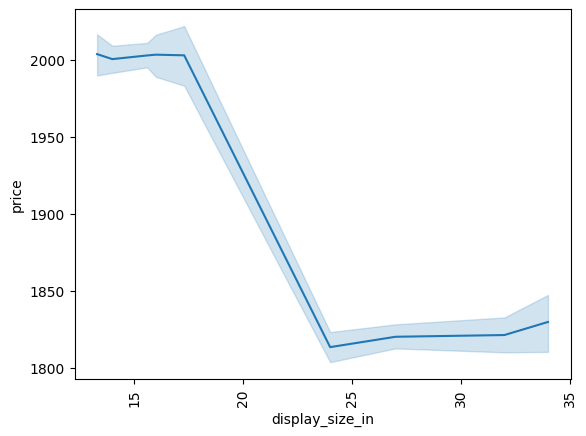

In [33]:
sns.lineplot(x=df['display_size_in'],y=df['price'])
plt.xticks(rotation='vertical')
plt.show()

In [34]:
new=df['resolution'].str.split('x',n=1,expand=True)

In [35]:
df['x_res'] = new[0]
df['y_res'] = new[1]
df.head()

,device_type,brand,model,release_year,os,form_factor,cpu_brand,cpu_model,cpu_tier,cpu_cores,...,battery_wh,charger_watts,psu_watts,wifi,bluetooth,weight_kg,warranty_months,price,x_res,y_res
0,Desktop,Samsung,Samsung Forge XDI,2022,Windows,ATX,Intel,Intel i5-11129,3,12,...,0,0,750,Wi-Fi 6,5.1,11.00,36,1384,2560,1440
1,Laptop,Samsung,Samsung Pro KM8,2022,Windows,Mainstream,Intel,Intel i7-11114,4,12,...,56,120,0,Wi-Fi 6,5.3,2.03,12,2275,1920,1080
2,Desktop,Lenovo,Lenovo Strix BIE,2024,macOS,SFF,AMD,AMD Ryzen 5 5168,2,8,...,0,0,850,Wi-Fi 6,5.0,7.00,24,1880,3440,1440
3,Desktop,Dell,Dell Cube AXR,2024,Windows,ATX,AMD,AMD Ryzen 5 7550,2,6,...,0,0,650,Wi-Fi 6,5.2,6.00,36,1332,3440,1440
4,Laptop,Gigabyte,Gigabyte Pro IX1,2024,Linux,Gaming,AMD,AMD Ryzen 7 6230,5,16,...,80,90,0,Wi-Fi 6,5.2,1.50,12,2682,2560,1600


In [36]:
df['x_res']=df['x_res'].astype(int)
df['y_res']=df['y_res'].astype(int)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 35 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   model                100000 non-null  object 
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  object 
 5   form_factor          100000 non-null  object 
 6   cpu_brand            100000 non-null  object 
 7   cpu_model            100000 non-null  object 
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  cpu_base_ghz         100000 non-null  float64
 12  cpu_boost_ghz        100000 non-null  float64
 13  gpu_brand            100000 non-null  object 
 14  gpu_model            100000 non-null  object 
 15  gpu_tier          

In [37]:
df.select_dtypes(include=['number']).corr()['price']

release_year           0.089721
cpu_tier               0.759196
cpu_cores              0.720464
cpu_threads            0.577503
cpu_base_ghz           0.529910
cpu_boost_ghz          0.508507
gpu_tier               0.762875
vram_gb                0.305017
ram_gb                 0.758654
storage_gb             0.088937
storage_drive_count   -0.082437
display_size_in       -0.143405
refresh_hz             0.077244
battery_wh             0.147212
charger_watts          0.126309
psu_watts             -0.140530
bluetooth              0.002076
weight_kg             -0.130727
warranty_months       -0.002138
price                  1.000000
x_res                  0.166524
y_res                  0.188524
Name: price, dtype: float64

In [38]:
df['ppi'] = (((df['x_res'] ** 2) + (df['y_res'] ** 2)) ** 0.5) / df['display_size_in'].astype('float')
df.select_dtypes(include=['number']).corr()['price']


release_year           0.089721
cpu_tier               0.759196
cpu_cores              0.720464
cpu_threads            0.577503
cpu_base_ghz           0.529910
cpu_boost_ghz          0.508507
gpu_tier               0.762875
vram_gb                0.305017
ram_gb                 0.758654
storage_gb             0.088937
storage_drive_count   -0.082437
display_size_in       -0.143405
refresh_hz             0.077244
battery_wh             0.147212
charger_watts          0.126309
psu_watts             -0.140530
bluetooth              0.002076
weight_kg             -0.130727
warranty_months       -0.002138
price                  1.000000
x_res                  0.166524
y_res                  0.188524
ppi                    0.235364
Name: price, dtype: float64

In [39]:

print("\nCPU model examples:")
print(df[["cpu_brand", "cpu_model", "cpu_tier"]].sample(15, random_state=42).to_string(index=False))


CPU model examples:
cpu_brand        cpu_model  cpu_tier
      AMD AMD Ryzen 5 5509         3
      AMD AMD Ryzen 3 5589         1
      AMD AMD Ryzen 7 3229         5
      AMD AMD Ryzen 7 5422         4
    Intel   Intel i5-11623         3
      AMD AMD Ryzen 3 3279         1
    Apple         Apple M1         2
    Intel   Intel i9-11181         6
      AMD AMD Ryzen 3 5863         1
    Apple     Apple M3 Pro         4
    Intel   Intel i3-10252         1
    Apple     Apple M2 Pro         5
    Intel   Intel i7-10656         5
    Intel   Intel i5-11661         3
      AMD AMD Ryzen 5 5398         3


In [40]:
print(
    df.groupby("cpu_brand")["cpu_model"]
      .nunique()
)

print("\nCPU models by brand:")
for brand in df["cpu_brand"].unique():
    print(f"\n{brand}:")
    print(
        df.loc[df["cpu_brand"] == brand, "cpu_model"]
          .value_counts()
          .head(10)
    )

cpu_brand
AMD      12755
Apple        9
Intel    14207
Name: cpu_model, dtype: int64

CPU models by brand:

Intel:
cpu_model
Intel i5-13475    14
Intel i5-14535    14
Intel i5-10630    14
Intel i5-10828    14
Intel i5-10434    14
Intel i5-14497    14
Intel i5-10243    13
Intel i5-10132    13
Intel i5-10928    13
Intel i5-12116    13
Name: count, dtype: int64

AMD:
cpu_model
AMD Ryzen 5 3553    14
AMD Ryzen 5 6625    13
AMD Ryzen 5 4503    12
AMD Ryzen 5 7156    12
AMD Ryzen 5 4234    12
AMD Ryzen 5 3998    12
AMD Ryzen 5 6200    11
AMD Ryzen 5 4478    11
AMD Ryzen 5 6756    11
AMD Ryzen 5 5752    11
Name: count, dtype: int64

Apple:
cpu_model
Apple M2 Pro    1389
Apple M1        1374
Apple M2 Max    1367
Apple M1 Pro    1341
Apple M3 Pro    1315
Apple M3 Max    1300
Apple M3        1287
Apple M1 Max    1277
Apple M2        1265
Name: count, dtype: int64


In [41]:

def get_cpu_family(model):
    if pd.isna(model):
        return "Unknown"

    model = model.lower()

    if "apple" in model:
        return model.replace("apple ", "").title()

    if "intel" in model:
        if "i3-" in model:
            return "Intel Core i3"
        elif "i5-" in model:
            return "Intel Core i5"
        elif "i7-" in model:
            return "Intel Core i7"
        elif "i9-" in model:
            return "Intel Core i9"
        return "Intel Other"

    if "amd" in model:
        if "ryzen 3" in model:
            return "AMD Ryzen 3"
        elif "ryzen 5" in model:
            return "AMD Ryzen 5"
        elif "ryzen 7" in model:
            return "AMD Ryzen 7"
        elif "ryzen 9" in model:
            return "AMD Ryzen 9"
        return "AMD Other"

    return "Other"

df["cpu_family"] = df["cpu_model"].apply(get_cpu_family)

print(df["cpu_family"].value_counts())

cpu_family
Intel Core i5    25233
Intel Core i7    17991
AMD Ryzen 5      17014
AMD Ryzen 7      11976
Intel Core i3     7354
AMD Ryzen 3       4966
Intel Core i9     2196
M2 Pro            1389
M1                1374
M2 Max            1367
AMD Ryzen 9       1355
M1 Pro            1341
M3 Pro            1315
M3 Max            1300
M3                1287
M1 Max            1277
M2                1265
Name: count, dtype: int64


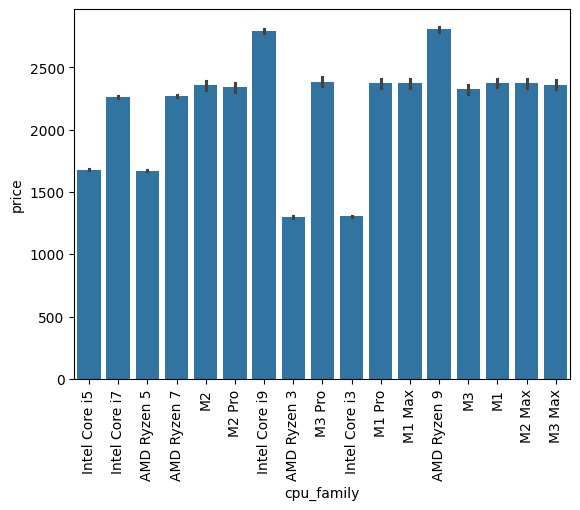

In [42]:
sns.barplot(x=df['cpu_family'],y=df['price'])
plt.xticks(rotation='vertical')
plt.show()

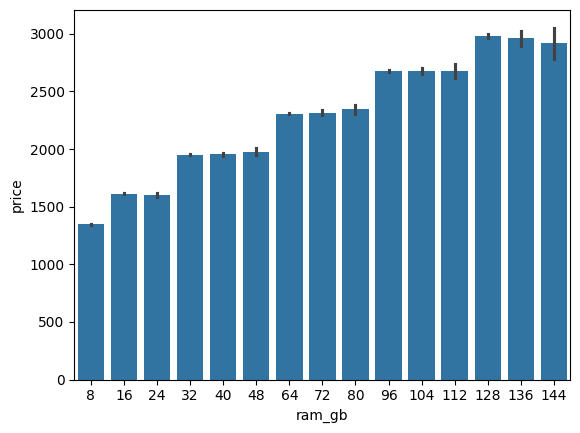

In [43]:
sns.barplot(x=df['ram_gb'],y=df['price'])
plt.show()

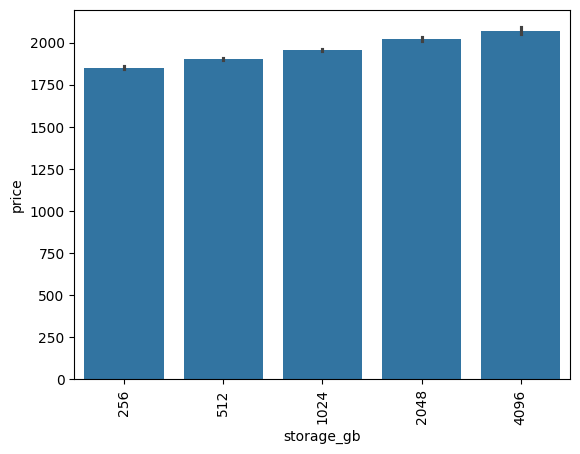

In [44]:
sns.barplot(x=df['storage_gb'],y=df['price'])
plt.xticks(rotation='vertical')
plt.show()

In [45]:
# Storage: SSD, NVMe and Hybrid all price like SSD; only plain HDD is 'hdd'
df['ssd_gb'] = np.where(df['storage_type'].isin(['SSD','NVMe','Hybrid']), df['storage_gb'], 0)
df['hdd_gb'] = np.where(df['storage_type'] == 'HDD', df['storage_gb'], 0)

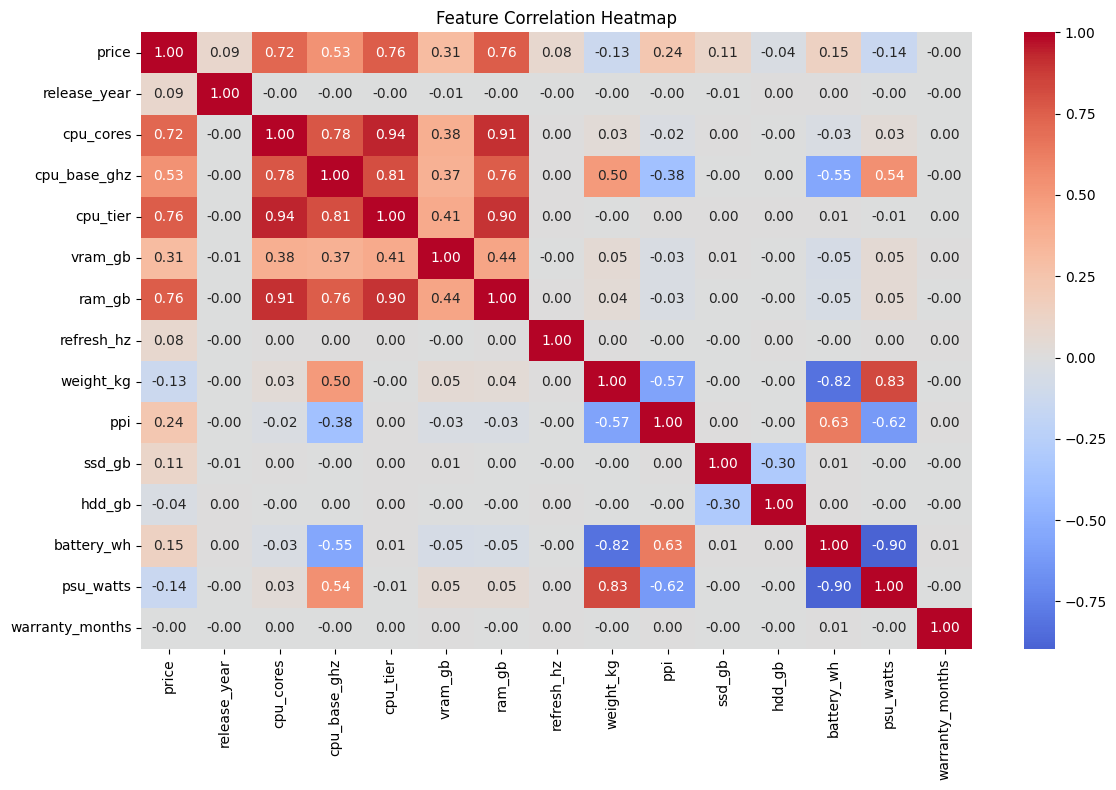

In [46]:
heatmap_cols = [
    'price',
    'release_year',
    'cpu_cores',
    'cpu_base_ghz',
    'cpu_tier',
    'vram_gb',
    'ram_gb',
    'refresh_hz',
    'weight_kg',
    'ppi',
    'ssd_gb',
    'hdd_gb',
    'battery_wh',
    'psu_watts',
    'warranty_months'
]

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[heatmap_cols].corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [47]:
# Proof of the problem: device_type is fully determined by other columns
print(df.groupby('device_type')[['battery_wh','psu_watts']].agg(['min','max']))
print(pd.crosstab(df['form_factor'], df['device_type']))

            battery_wh     psu_watts      
                   min max       min   max
device_type                               
Desktop              0   0       300  1200
Laptop              50  99         0     0
device_type  Desktop  Laptop
form_factor                 
2-in-1             0    7049
ATX            15597       0
Full-Tower      7110       0
Gaming             0   16876
Mainstream         0   17819
Micro-ATX       8672       0
Mini-ITX        3192       0
SFF             5585       0
Ultrabook          0   13236
Workstation        0    4864


Model Training with Comparisons

In [49]:
import pickle, warnings
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import Ridge,LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor,GradientBoostingRegressor,ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from price_model import FEATURES, DevicePriceModel  
from xgboost import XGBRegressor


def candidates():
    return {"Linear Regression": LinearRegression(),
            'RandomForest': RandomForestRegressor(200, min_samples_leaf=3, n_jobs=-1, random_state=42),
            'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42),
            "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42 ),
            "Extra Trees": ExtraTreesRegressor( n_estimators=100, random_state=42, n_jobs=-1),
            "XGBoost": XGBRegressor( n_estimators=100, max_depth=5, learning_rate=0.1,random_state=42, n_jobs=-1
                )}

models, names = {}, {}
for dt in ['Laptop', 'Desktop']:
    d = df[df['device_type'] == dt]
    X, y = d[FEATURES[dt]], np.log(d['price'])

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    cat = X.select_dtypes(exclude='number').columns.tolist()

    best_mae, best_name, best_pipe = np.inf, None, None

    for name, est in candidates().items():
        pipe = Pipeline([('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)],
                                                    remainder='passthrough')),
                         ('model', est)]).fit(X_train, y_train)
        
        pred = np.exp(pipe.predict(X_test)); actual = np.exp(y_test)

        mae, r2 = mean_absolute_error(actual, pred), r2_score(actual, pred)

        print(f'{dt:8s} {name:22s} MAE=${mae:7.2f}  R2={r2:.4f}')
        
        if mae < best_mae: best_mae, best_name, best_pipe = mae, name, pipe
    print(f'  -> best for {dt}: {best_name}\n')
    models[dt] = Pipeline(best_pipe.steps).fit(X, y)       # refit winner on all rows of this device type
    names[dt] = best_name

final_model = DevicePriceModel(models, names)

Laptop   Linear Regression      MAE=$ 153.33  R2=0.8592
Laptop   RandomForest           MAE=$ 161.25  R2=0.8490
Laptop   HistGradientBoosting   MAE=$ 143.65  R2=0.8735
Laptop   Gradient Boosting      MAE=$ 150.63  R2=0.8642
Laptop   Extra Trees            MAE=$ 166.38  R2=0.8381
Laptop   XGBoost                MAE=$ 145.41  R2=0.8714
  -> best for Laptop: HistGradientBoosting

Desktop  Linear Regression      MAE=$ 146.32  R2=0.8257
Desktop  RandomForest           MAE=$ 150.28  R2=0.8181
Desktop  HistGradientBoosting   MAE=$ 135.43  R2=0.8422
Desktop  Gradient Boosting      MAE=$ 141.79  R2=0.8331
Desktop  Extra Trees            MAE=$ 156.83  R2=0.7935
Desktop  XGBoost                MAE=$ 136.63  R2=0.8412
  -> best for Desktop: HistGradientBoosting



In [ ]:
pickle.dump(final_model, open('model.pkl', 'wb'))

# save only the columns the app uses -> df.pkl is about 7 MB instead of 28 MB
cols = ['device_type', 'brand', 'release_year', 'os', 'warranty_months', 'cpu_cores', 'gpu_brand', 'vram_gb',
        'ram_gb', 'storage_drive_count', 'refresh_hz', 'display_type', 'resolution', 'display_size_in']
pickle.dump(df[cols], open('df.pkl', 'wb'))
